# DSCI 552 — Homework 7: SVMs for Multi-Label Classification and K-Means Clustering

Classifying frog calls by family, genus, and species from 22 MFCC audio features (UCI **Anuran Calls** data set), using binary-relevance support vector machines, SMOTE, and k-means clustering, plus ISLR exercise 12.6.2.

## Setup

The data is not included in this repository. Download the [Anuran Calls (MFCCs)](https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29) data set from UCI and unzip it anywhere below the folder this notebook runs from; `Frogs_MFCCs.csv` is located automatically. Requires `pip install imbalanced-learn`.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")

data_path = next(Path(".").rglob("Frogs_MFCCs.csv"))
print(data_path)

Anuran Calls (MFCCs)/Frogs_MFCCs.csv


## 1. Multi-class and Multi-label Classification Using SVMs

### 1(a) Loading the data and the 70/30 split

The data set has 7,195 calls, 22 MFCC features, and three labels: Family (4 classes), Genus (8), and Species (10). `RecordID` is not used as a feature. 70% of the data is chosen at random as the training set; the split is stratified by species so that even the rarest species appears in both sets.

In [ ]:
frogs = pd.read_csv(data_path)
labels = ["Family", "Genus", "Species"]
features = [c for c in frogs.columns if c.startswith("MFCC")]

X = frogs[features]
Y = frogs[labels]
print(X.shape, Y.shape)
print(Y.nunique())

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=0, stratify=Y["Species"])
print(X_train.shape, X_test.shape)

(7195, 22) (7195, 3)
Family      4
Genus       8
Species    10
dtype: int64
(5036, 22) (2159, 22)


Class counts in the training set:

In [ ]:
for lab in labels:
    print(Y_train[lab].value_counts(), "\n")

Family
Leptodactylidae    3093
Hylidae            1516
Dendrobatidae       379
Bufonidae            48
Name: count, dtype: int64 

Genus
Adenomera        2904
Hypsiboas        1115
Ameerega          379
Dendropsophus     217
Leptodactylus     189
Scinax            104
Osteocephalus      80
Rhinella           48
Name: count, dtype: int64 

Species
AdenomeraHylaedactylus    2434
HypsiboasCordobae          785
AdenomeraAndre             470
Ameeregatrivittata         379
HypsiboasCinerascens       330
HylaMinuta                 217
LeptodactylusFuscus        189
ScinaxRuber                104
OsteocephalusOophagus       80
Rhinellagranulosa           48
Name: count, dtype: int64 



All three labels are imbalanced: for example, *Adenomera hylaedactylus* has 2,434 training calls, while *Rhinella granulosa* has only 48.

### 1(b)i Evaluation metrics for multi-label classification

Each call has a true label triplet (family, genus, species) and a predicted triplet.

- **Exact match ratio:** the fraction of calls for which **all three** labels are predicted correctly. This is the strictest measure, since a single wrong label makes the whole prediction count as wrong.
- **Hamming loss:** the fraction of **individual labels** that are predicted incorrectly, averaged over all calls and all labels: $\frac{1}{n\,L}\sum_{i=1}^{n}\sum_{l=1}^{L} \mathbb{1}(\hat y_{il} \ne y_{il})$ with $L = 3$. It gives partial credit, so a call with only the species wrong contributes 1/3.
- **Hamming score:** 1 − Hamming loss, the fraction of individual labels predicted correctly.

In the multi-label literature (e.g., Sorower's survey), the Hamming score is often defined with a Jaccard-style formula for binary label vectors. Here each of the three label "slots" holds exactly one class, so the slot-wise accuracy above is the natural version.

In [ ]:
def multilabel_scores(Y_true, Y_pred):
    wrong = (np.asarray(Y_true) != np.asarray(Y_pred))   # True where a label is wrong
    return {
        "exact_match":   (~wrong.any(axis=1)).mean(),
        "hamming_loss":  wrong.mean(),
        "hamming_score": 1 - wrong.mean(),
    }

results = {}
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

**Binary relevance.** One classifier is trained for each label independently. For each label, the hyperparameters are tuned by stratified 10-fold cross-validation on the training set; the three predictions are then combined into a predicted triplet and evaluated on the test set.

In [ ]:
def run_binary_relevance(name, make_model, grid, Xtr, Xte):
    preds = {}
    for lab in labels:
        gs = GridSearchCV(make_model(), grid, cv=cv10, scoring="accuracy", n_jobs=-1)
        gs.fit(Xtr, Y_train[lab])
        preds[lab] = gs.predict(Xte)
        test_acc = (preds[lab] == Y_test[lab].values).mean()
        print(f"{name} | {lab:8s} best {gs.best_params_}  CV acc {gs.best_score_:.4f}  test acc {test_acc:.4f}")
    Y_pred = pd.DataFrame(preds)[labels]
    results[name] = multilabel_scores(Y_test, Y_pred)
    print(name, {k: round(v, 4) for k, v in results[name].items()}, "\n")

### 1(b)ii Gaussian-kernel SVMs (one-vs-all)

Each label gets an RBF-kernel SVM wrapped in `OneVsRestClassifier`, giving one-vs-all classifiers (sklearn's `SVC` alone uses one-vs-one). The penalty weight $C$ and the kernel width are tuned by 10-fold CV. sklearn parameterizes the RBF kernel as $\exp(-\gamma\|x - x'\|^2)$, so $\gamma = 1/(2\sigma^2)$: a large $\gamma$ means a narrow kernel and a more flexible boundary.

**Raw attributes:**

In [ ]:
rbf_grid = {"estimator__C": [0.1, 1, 10, 100, 1000],
            "estimator__gamma": [0.01, 0.1, 0.5, 1, 2, 5]}

def make_rbf():
    return OneVsRestClassifier(SVC(kernel="rbf"))

run_binary_relevance("Gaussian SVM (raw)", make_rbf, rbf_grid, X_train, X_test)

Gaussian SVM (raw) | Family   best {'estimator__C': 10, 'estimator__gamma': 5}  CV acc 0.9931  test acc 0.9898
Gaussian SVM (raw) | Genus    best {'estimator__C': 100, 'estimator__gamma': 2}  CV acc 0.9909  test acc 0.9889
Gaussian SVM (raw) | Species  best {'estimator__C': 10, 'estimator__gamma': 5}  CV acc 0.9907  test acc 0.9875
Gaussian SVM (raw) {'exact_match': np.float64(0.9824), 'hamming_loss': np.float64(0.0113), 'hamming_score': np.float64(0.9887)} 



**Standardized attributes:**

In [ ]:
def make_rbf_std():
    return Pipeline([("scale", StandardScaler()),
                     ("svm", OneVsRestClassifier(SVC(kernel="rbf")))])

rbf_grid_std = {"svm__estimator__C": [0.1, 1, 10, 100, 1000],
                "svm__estimator__gamma": [0.01, 0.05, 0.1, 0.5, 1]}

run_binary_relevance("Gaussian SVM (standardized)", make_rbf_std, rbf_grid_std, X_train, X_test)

Gaussian SVM (standardized) | Family   best {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.05}  CV acc 0.9931  test acc 0.9917
Gaussian SVM (standardized) | Genus    best {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.05}  CV acc 0.9909  test acc 0.9884
Gaussian SVM (standardized) | Species  best {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}  CV acc 0.9899  test acc 0.9819
Gaussian SVM (standardized) {'exact_match': np.float64(0.981), 'hamming_loss': np.float64(0.0127), 'hamming_score': np.float64(0.9873)} 



Both versions perform extremely well: about 98% of calls get all three labels right, and only about 1.2% of individual labels are wrong. The raw and standardized versions are nearly identical (exact match 0.982 vs. 0.981), which agrees with footnote 2: the MFCCs are already on a similar scale, so standardizing changes little. For the standardized features, all selected values lie inside the grid. For the raw features, the selected $\gamma = 5$ for Family and Species is at the upper edge of the grid, so a slightly larger $\gamma$ might do marginally better; however, cross-validation accuracy is already about 0.99, so there is little room for improvement.

### 1(b)iii L1-penalized linear SVMs

Following the convention in footnote 3, the L1 penalty is used with a linear kernel (`LinearSVC`, which is one-vs-rest for multiclass labels). The features are standardized inside the pipeline, and $C$ is tuned by 10-fold CV.

In [ ]:
def make_l1():
    return Pipeline([("scale", StandardScaler()),
                     ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000))])

l1_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100]}

run_binary_relevance("L1 linear SVM", make_l1, l1_grid, X_train, X_test)

L1 linear SVM | Family   best {'svm__C': 100}  CV acc 0.9369  test acc 0.9328
L1 linear SVM | Genus    best {'svm__C': 100}  CV acc 0.9525  test acc 0.9430
L1 linear SVM | Species  best {'svm__C': 100}  CV acc 0.9601  test acc 0.9528
L1 linear SVM {'exact_match': np.float64(0.9138), 'hamming_loss': np.float64(0.0571), 'hamming_score': np.float64(0.9429)} 



The L1 linear SVMs are clearly worse than the Gaussian SVMs (exact match 0.914 vs. 0.982), because a linear boundary cannot capture the non-linear class structure in the MFCC space. The selected $C = 100$ is the largest value in the grid for all three labels, i.e., the weakest penalty: the linear model benefits from as little shrinkage as possible, which is consistent with underfitting rather than overfitting.

### 1(b)iv L1 linear SVMs with SMOTE

SMOTE is placed **inside** the pipeline, so in each cross-validation fold only the training portion is oversampled and the validation portion keeps its real class balance. For a multiclass label, SMOTE oversamples every minority class up to the size of the largest class.

In [ ]:
def make_l1_smote():
    return ImbPipeline([("scale", StandardScaler()),
                        ("smote", SMOTE(random_state=0)),
                        ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000))])

run_binary_relevance("L1 linear SVM + SMOTE", make_l1_smote, l1_grid, X_train, X_test)

L1 linear SVM + SMOTE | Family   best {'svm__C': 1}  CV acc 0.9180  test acc 0.9203
L1 linear SVM + SMOTE | Genus    best {'svm__C': 1}  CV acc 0.9160  test acc 0.9222
L1 linear SVM + SMOTE | Species  best {'svm__C': 1}  CV acc 0.9565  test acc 0.9555
L1 linear SVM + SMOTE {'exact_match': np.float64(0.8717), 'hamming_loss': np.float64(0.0673), 'hamming_score': np.float64(0.9327)} 



### Summary of the classifiers

In [ ]:
pd.DataFrame(results).T.round(4)

,exact_match,hamming_loss,hamming_score
Gaussian SVM (raw),0.9824,0.0113,0.9887
Gaussian SVM (standardized),0.9810,0.0127,0.9873
L1 linear SVM,0.9138,0.0571,0.9429
L1 linear SVM + SMOTE,0.8717,0.0673,0.9327


**Conclusions:**
- **The Gaussian-kernel SVMs are by far the best** (exact match ≈ 0.98, Hamming loss ≈ 0.012). The class boundaries in the MFCC space are non-linear, and the RBF kernel captures them. Binary relevance works well here because each per-label classifier is very accurate on its own.
- **The L1 linear SVMs are noticeably worse** (exact match 0.914), because of their linear boundaries.
- **SMOTE did not help overall:** exact match fell from 0.914 to 0.872 and Hamming loss rose from 0.057 to 0.067. Species accuracy improved slightly (0.953 → 0.956), consistent with better treatment of the rare species, but Family and Genus accuracy dropped (0.933 → 0.920 and 0.943 → 0.922). With a linear classifier, balancing the classes shifts the boundaries toward the minority classes and causes more errors on the large classes, which dominate these metrics. A consequence of binary relevance is also visible here: because the three labels are predicted independently, the predicted triplet can be inconsistent (e.g., a species paired with the wrong genus), which lowers the exact match ratio more than any single label accuracy suggests.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

**Procedure (repeated 50 times with different random seeds):**
1. Fit k-means on the whole data set for $k = 2, \dots, 50$ and choose the $k$ that maximizes the **Calinski–Harabasz (CH) index**, the ratio of between-cluster to within-cluster dispersion (higher is better). The CH index is undefined for $k = 1$, which has no between-cluster dispersion.
2. Refit k-means with the chosen $k$.
3. In each cluster, assign the majority family, genus, and species according to the true labels.
4. Compare each call's true triplet with its cluster's majority triplet. The **Hamming distance** of a call is the number of the three labels that differ (0–3); the **Hamming loss** is the distance divided by 3, and the **Hamming score** is 1 − loss.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

def kmeans_run(seed):
    ch = {}
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X)
        ch[k] = calinski_harabasz_score(X, km.labels_)
    best_k = max(ch, key=ch.get)

    km = KMeans(n_clusters=best_k, n_init=10, random_state=seed).fit(X)
    pred = pd.DataFrame(index=Y.index)
    for lab in labels:
        majority = Y[lab].groupby(km.labels_).agg(lambda s: s.mode()[0])
        pred[lab] = majority.loc[km.labels_].values

    wrong = (Y.values != pred[labels].values)
    return {"k": best_k,
            "hamming_distance": wrong.sum(axis=1).mean(),
            "hamming_loss": wrong.mean(),
            "hamming_score": 1 - wrong.mean()}, ch

runs = []
for seed in range(50):
    res, ch = kmeans_run(seed)
    runs.append(res)
    if seed == 0:
        ch_first = ch
    if seed % 10 == 9:
        print("finished run", seed + 1)

mc = pd.DataFrame(runs)
print(mc["k"].value_counts())
mc.agg(["mean", "std"]).round(4)

finished run 10
finished run 20
finished run 30
finished run 40
finished run 50
k
2    50
Name: count, dtype: int64


,k,hamming_distance,hamming_loss,hamming_score
mean,2.0,0.8956,0.2985,0.7015
std,0.0,0.0000,0.0000,0.0000


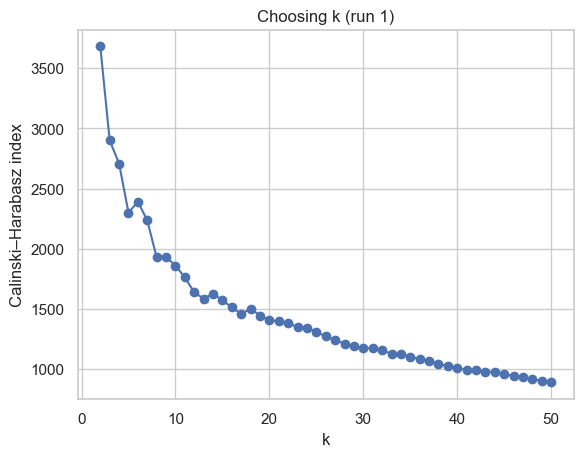

In [ ]:
plt.plot(list(ch_first.keys()), list(ch_first.values()), marker="o")
plt.xlabel("k"); plt.ylabel("Calinski–Harabasz index")
plt.title("Choosing k (run 1)")
plt.show()

**Results.** The CH index decreases almost monotonically with $k$ and is largest at $k = 2$, which was chosen in **all 50 runs**. Over the 50 runs:

| | Mean | Standard deviation |
|---|---|---|
| Hamming distance | 0.8956 | 0.0000 |
| Hamming loss | 0.2985 | 0.0000 |
| Hamming score | 0.7015 | 0.0000 |

The standard deviation is 0 because, with $k = 2$, every run converges to the same partition, so the majority labels and the distances are identical. On average, about 0.9 of the 3 labels per call are wrong, and 70% of individual labels are correct.

This is far worse than the supervised SVMs (Hamming loss 0.30 vs. about 0.01). K-means never sees the labels, and with only 2 clusters it can assign at most 2 distinct species, so 8 of the 10 species can never be predicted. The CH index favors a coarse split here; other criteria (e.g., silhouettes or the gap statistic) might select more clusters and reduce the Hamming loss, at a higher computational cost.

## 3. ISLR 12.6.2

The dissimilarity matrix for four observations:

| | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| **1** | — | 0.3 | 0.4 | 0.7 |
| **2** | 0.3 | — | 0.5 | 0.8 |
| **3** | 0.4 | 0.5 | — | 0.45 |
| **4** | 0.7 | 0.8 | 0.45 | — |

**(a) Complete linkage** (the dissimilarity between clusters is the *largest* pairwise dissimilarity):
1. The smallest dissimilarity is 0.3, so {1, 2} fuse at height **0.3**.
2. Updated dissimilarities: {1,2}–3 = max(0.4, 0.5) = 0.5; {1,2}–4 = max(0.7, 0.8) = 0.8; 3–4 = 0.45. So {3, 4} fuse at height **0.45**.
3. {1,2}–{3,4} = max(0.4, 0.7, 0.5, 0.8) = 0.8, so all four fuse at height **0.8**.

**(b) Single linkage** (the *smallest* pairwise dissimilarity):
1. {1, 2} fuse at height **0.3**.
2. Updated dissimilarities: {1,2}–3 = min(0.4, 0.5) = 0.4; {1,2}–4 = min(0.7, 0.8) = 0.7; 3–4 = 0.45. So 3 joins {1, 2} at height **0.4**.
3. {1,2,3}–4 = min(0.7, 0.8, 0.45) = 0.45, so 4 joins at height **0.45**.

**(c)** Cutting the complete-linkage dendrogram into two clusters gives **{1, 2} and {3, 4}**.

**(d)** Cutting the single-linkage dendrogram into two clusters gives **{1, 2, 3} and {4}**.

**(e)** The two branches at any fusion can be swapped without changing the meaning of the dendrogram. Swapping the leaves within each pair of the complete-linkage dendrogram gives the leaf order **2, 1, 4, 3**, which represents exactly the same clustering (panel (e) below).

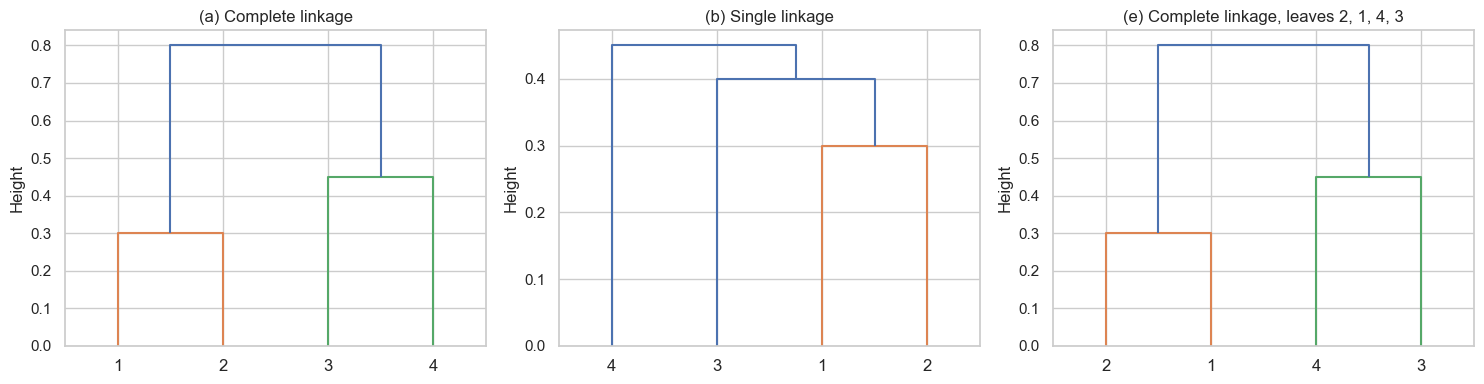

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

D = np.array([[0, 0.3, 0.4, 0.7],
              [0.3, 0, 0.5, 0.8],
              [0.4, 0.5, 0, 0.45],
              [0.7, 0.8, 0.45, 0]])
d = squareform(D)
leaves = ["1", "2", "3", "4"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
dendrogram(linkage(d, "complete"), labels=leaves, ax=axes[0])
axes[0].set_title("(a) Complete linkage")
dendrogram(linkage(d, "single"), labels=leaves, ax=axes[1])
axes[1].set_title("(b) Single linkage")
dendrogram(linkage(d, "complete"), labels=leaves, ax=axes[2])
axes[2].set_xticklabels(["2", "1", "4", "3"])
axes[2].set_title("(e) Complete linkage, leaves 2, 1, 4, 3")
for ax in axes:
    ax.set_ylabel("Height")
plt.tight_layout()
plt.show()